In [1]:
import json, re, unicodedata, warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.pipeline import Pipeline, FeatureUnion        
from sklearn.model_selection import (train_test_split,
                                     StratifiedKFold,
                                     cross_val_score)
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)

import matplotlib.pyplot as plt
%matplotlib inline

required = ['json', 're', 'unicodedata', 'pd', 'np', 'nltk',
            'stopwords', 'WordNetLemmatizer',
            'TfidfVectorizer', 'SelectKBest', 'chi2',
            'Pipeline', 'FeatureUnion',
            'train_test_split', 'StratifiedKFold', 'cross_val_score',
            'MultinomialNB',
            'classification_report', 'confusion_matrix',
            'roc_auc_score', 'roc_curve', 'ConfusionMatrixDisplay',
            'plt']

missing = [name for name in required if name not in dir()]
if missing:
    print("MISSING:", missing)
else:
    print("All required names are defined. You can safely run the rest of the notebook.")

MISSING: ['json', 're', 'unicodedata', 'pd', 'np', 'nltk', 'stopwords', 'WordNetLemmatizer', 'TfidfVectorizer', 'SelectKBest', 'chi2', 'Pipeline', 'FeatureUnion', 'train_test_split', 'StratifiedKFold', 'cross_val_score', 'MultinomialNB', 'classification_report', 'confusion_matrix', 'roc_auc_score', 'roc_curve', 'ConfusionMatrixDisplay', 'plt']


In [2]:
for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'punkt']:
    nltk.download(pkg, quiet=True)
print("NLTK resources ready")

NLTK resources ready


In [3]:
with open("C:\\Users\\User\\Downloads\\Project 1 Required Resources-20261110\\research_abstracts.json", 'r') as f:
    raw = json.load(f)

df = pd.DataFrame({
    'DOI':      raw['DOI'],
    'Abstract': raw['Abstract'],
    'Label':    raw['Label'],
})

print(f"Raw rows loaded: {len(df)}")
print(df['Label'].value_counts(dropna=False))
df.head(3)

Raw rows loaded: 1138
Label
classical    900
ai           238
Name: count, dtype: int64


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical


In [4]:
df = df.dropna(subset=['Abstract', 'Label']).reset_index(drop=True)

print(f"Rows with abstract + label: {len(df)}")
print("\nLabel distribution:")
print(df['Label'].value_counts())
print(f"\nClass balance (%):\n{(df['Label'].value_counts(normalize=True)*100).round(1)}")

Rows with abstract + label: 1138

Label distribution:
Label
classical    900
ai           238
Name: count, dtype: int64

Class balance (%):
Label
classical    79.1
ai           20.9
Name: proportion, dtype: float64


In [5]:
STOP = set(stopwords.words('english'))
LEMM = WordNetLemmatizer()

BOILERPLATE = re.compile(
    r'\b(abstract|purpose|design[/ ]methodology[/ ]approach|findings?|'
    r'originality[/ ]value|research limitations?[/ ]implications?|'
    r'practical implications?|social implications?|paper type|keywords?)\b',
    re.I)

def denoise(text: str) -> str:
    """Clean raw abstract text of markup, URLs, DOIs and boilerplate."""
    if not isinstance(text, str):
        return ""
    t = unicodedata.normalize('NFKD', text)
    t = t.encode('ascii', 'ignore').decode('ascii')        
    t = re.sub(r'\[Formula:[^\]]*\]', ' ', t)              
    t = re.sub(r'\$[^$]*\$', ' ', t)                       
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)           
    t = re.sub(r'\b10\.\d{4,9}/\S+', ' ', t)              
    t = re.sub(r'&[a-z]+;|&#\d+;', ' ', t)                
    t = re.sub(r'<[^>]+>', ' ', t)                         
    t = BOILERPLATE.sub(' ', t)                            
    t = re.sub(r'\([^)]{0,60}\)', ' ', t)                  
    t = re.sub(r'[^a-zA-Z\s]', ' ', t)                    
    t = re.sub(r'\s+', ' ', t).strip().lower()
    return t

def tokenize_lemma(text: str) -> str:
    """Remove stopwords, short tokens, then lemmatise each word."""
    toks = [w for w in text.split() if w not in STOP and len(w) > 2]
    return ' '.join(LEMM.lemmatize(w) for w in toks)

print("Denoising functions defined")

Denoising functions defined


In [6]:
df['clean']  = df['Abstract'].map(denoise)
df['tokens'] = df['clean'].map(tokenize_lemma)

i = 0
print("RAW     :", df.loc[i, 'Abstract'][:300], "...\n")
print("CLEANED :", df.loc[i, 'tokens'][:300], "...")

RAW     : Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutio ...

CLEANED : forward looking forecasting inflation rate could help central bank government department better use monetary policy stabilize price prevent impact inflation market entity especially low middle income group also help financial institution investor better make investment decision sense forecast inflat ...


In [7]:
df['n_tokens'] = df['tokens'].str.split().str.len()

print("Token count summary:")
print(df['n_tokens'].describe().round(1))

# Very short docs are noise
df = df[df['n_tokens'] >= 20].reset_index(drop=True)
print(f"\nUsable documents after length filter: {len(df)}")
print(df['Label'].value_counts())

Token count summary:
count    1138.0
mean      102.3
std        61.5
min         9.0
25%        70.0
50%        92.0
75%       119.8
max      1289.0
Name: n_tokens, dtype: float64

Usable documents after length filter: 1136
Label
classical    899
ai           237
Name: count, dtype: int64


In [8]:
y = df['Label'].map({'classical': 0, 'ai': 1}).values
print("Target distribution:", np.bincount(y))
print("Mapping: 0 = classical, 1 = ai")

Target distribution: [899 237]
Mapping: 0 = classical, 1 = ai


In [9]:
word_tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.85,
    sublinear_tf=True,
    max_features=15000,
)

char_tfidf = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=5,
    max_df=0.85,
    max_features=10000,
)

feature_union = FeatureUnion([
    ('word_tfidf', Pipeline([
        ('tfidf', word_tfidf),
        ('chi2',  SelectKBest(chi2, k=8000)),
    ])),
    ('char_tfidf', char_tfidf),
])

print("Feature pipeline constructed - not fitted yet")

Feature pipeline constructed - not fitted yet


In [10]:
X = feature_union.fit_transform(df['tokens'], y)

print(f"Final feature matrix shape : {X.shape}")
print(f"Non-zero values            : {X.nnz:,}")

word_pipe = feature_union.transformer_list[0][1]
selector  = word_pipe.named_steps['chi2']
vocab     = word_pipe.named_steps['tfidf'].get_feature_names_out()

top_idx = selector.scores_.argsort()[-15:][::-1]
print("\nTop-15 discriminative tokens by chi² score:")
for j in top_idx:
    print(f"  {vocab[j]:<20s}  chi²={selector.scores_[j]:8.1f}")

Final feature matrix shape : (1136, 18000)
Non-zero values            : 1,156,414

Top-15 discriminative tokens by chi² score:
  machine               chi²=    22.7
  neural                chi²=    21.3
  machine learning      chi²=    20.9
  network               chi²=    20.9
  neural network        chi²=    20.9
  learning              chi²=    20.1
  algorithm             chi²=    16.3
  quantile              chi²=     8.8
  artificial            chi²=     8.8
  forest                chi²=     8.6
  lstm                  chi²=     8.5
  learning model        chi²=     8.2
  random forest         chi²=     8.2
  svr                   chi²=     7.7
  sentiment             chi²=     7.4


In [11]:
X_text = df['tokens'].values

X_tr_txt, X_te_txt, y_tr, y_te = train_test_split(
    X_text, y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(f"Train samples: {len(X_tr_txt)}")
print(f"Test  samples: {len(X_te_txt)}")
print(f"Train class balance: {np.bincount(y_tr)}")
print(f"Test  class balance: {np.bincount(y_te)}")

Train samples: 908
Test  samples: 228
Train class balance: [719 189]
Test  class balance: [180  48]


In [12]:
full_pipeline = Pipeline([
    ('features', FeatureUnion([
        ('word_tfidf', Pipeline([
            ('tfidf', TfidfVectorizer(
                ngram_range=(1, 2), min_df=3, max_df=0.85,
                sublinear_tf=True, max_features=15000)),
            ('chi2', SelectKBest(chi2, k=8000)),
        ])),
        ('char_tfidf', TfidfVectorizer(
            analyzer='char_wb', ngram_range=(3, 5),
            min_df=5, max_df=0.85, max_features=10000)),
    ])),
    ('clf', MultinomialNB(alpha=1.0)),
])

print(full_pipeline)

Pipeline(steps=[('features',
                 FeatureUnion(transformer_list=[('word_tfidf',
                                                 Pipeline(steps=[('tfidf',
                                                                  TfidfVectorizer(max_df=0.85,
                                                                                  max_features=15000,
                                                                                  min_df=3,
                                                                                  ngram_range=(1,
                                                                                               2),
                                                                                  sublinear_tf=True)),
                                                                 ('chi2',
                                                                  SelectKBest(k=8000,
                                                                              score_

In [13]:
full_pipeline.fit(X_tr_txt, y_tr)

y_pred = full_pipeline.predict(X_te_txt)
y_prob = full_pipeline.predict_proba(X_te_txt)[:, 1]

print("Model fitted and test-set predictions generated")

Model fitted and test-set predictions generated


In [14]:
print("-" * 60)
print("        TEST-SET PERFORMANCE (GENERALISATION)")
print("-" * 60)
print(classification_report(y_te, y_pred,
                            target_names=['classical', 'ai'],
                            digits=3))
print(f"ROC-AUC: {roc_auc_score(y_te, y_prob):.4f}")

------------------------------------------------------------
        TEST-SET PERFORMANCE (GENERALISATION)
------------------------------------------------------------
              precision    recall  f1-score   support

   classical      0.837     1.000     0.911       180
          ai      1.000     0.271     0.426        48

    accuracy                          0.846       228
   macro avg      0.919     0.635     0.669       228
weighted avg      0.871     0.846     0.809       228

ROC-AUC: 0.9351


In [15]:
train_acc = full_pipeline.score(X_tr_txt, y_tr)
test_acc  = full_pipeline.score(X_te_txt, y_te)

print(f"Training accuracy     : {train_acc:.3f}")
print(f"Test accuracy         : {test_acc:.3f}")
print(f"Generalisation gap    : {train_acc - test_acc:+.3f}")

Training accuracy     : 0.892
Test accuracy         : 0.846
Generalisation gap    : +0.046


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    full_pipeline, X_text, y,
    cv=cv, scoring='accuracy', n_jobs=-1,
)

print(f"CV fold accuracies : {np.round(cv_scores, 3)}")
print(f"CV mean ± std      : {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

CV fold accuracies : [0.846 0.855 0.855 0.863 0.859]
CV mean ± std      : 0.856 ± 0.006


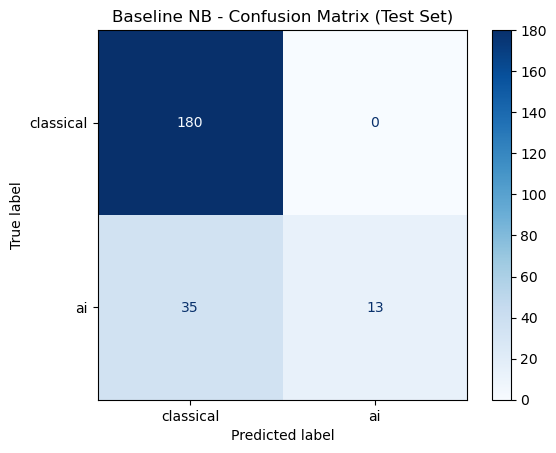

In [17]:
cm = confusion_matrix(y_te, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['classical', 'ai'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Baseline NB - Confusion Matrix (Test Set)")
plt.show()

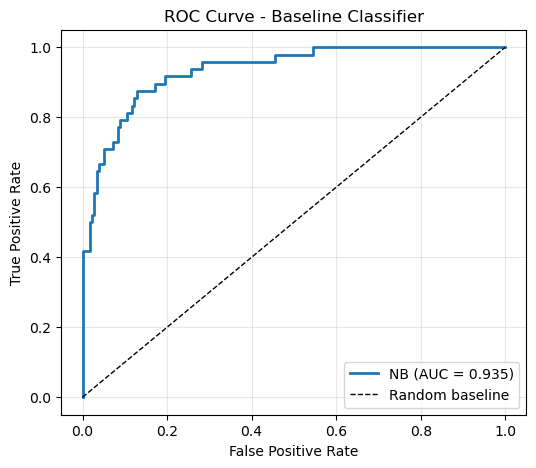

In [18]:
fpr, tpr, _ = roc_curve(y_te, y_prob)
auc_val     = roc_auc_score(y_te, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, lw=2, label=f'NB (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline Classifier')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
label_map = {0: 'classical', 1: 'ai'}
mis_idx   = np.where(y_pred != y_te)[0]

print(f"Total misclassifications: {len(mis_idx)} / {len(y_te)}")
print(f"  False negatives (ai --> classical): "
      f"{np.sum((y_te == 1) & (y_pred == 0))}")
print(f"  False positives (classical --> ai): "
      f"{np.sum((y_te == 0) & (y_pred == 1))}")

print("\nSample misclassified abstracts:")
for k in mis_idx[:5]:
    print(f"\n--- True: {label_map[y_te[k]]} | Predicted: {label_map[y_pred[k]]} ---")
    print(X_te_txt[k][:220], "...")

Total misclassifications: 35 / 228
  False negatives (ai --> classical): 35
  False positives (classical --> ai): 0

Sample misclassified abstracts:

--- True: ai | Predicted: classical ---
study specify efficient forecast model accurate prediction macroeconomic variable context pakistan particularly investigate comparative accuracy artificial neural network autoregressive integrated moving average model ba ...

--- True: ai | Predicted: classical ---
paper develops bayesian quantile regression model time varying parameter forecasting inflation risk proposed parametric methodology bridge empirically established benefit tvp regression forecasting inflation ability quan ...

--- True: ai | Predicted: classical ---
stock high risk high return investment risk comparison scale loss profit much different lure profit temptation given playing share sometimes make people less cautious eventually fail invest stock make right profitable in ...

--- True: ai | Predicted: classical ---
regional reg

In [20]:
summary = pd.DataFrame({
    'Metric': [
        'Train accuracy',
        'Test accuracy',
        '5-fold CV accuracy',
        'ROC-AUC',
        'Generalisation gap',
        'False negatives (ai --> classical)',
        'False positives (classical --> ai)',
    ],
    'Value': [
        f'{train_acc:.3f}',
        f'{test_acc:.3f}',
        f'{cv_scores.mean():.3f} ± {cv_scores.std():.3f}',
        f'{auc_val:.3f}',
        f'{train_acc - test_acc:+.3f}',
        f'{np.sum((y_te == 1) & (y_pred == 0))}',
        f'{np.sum((y_te == 0) & (y_pred == 1))}',
    ],
})

print("\n--- BASELINE MODEL - FINAL SUMMARY ---")
print(summary.to_string(index=False))


--- BASELINE MODEL - FINAL SUMMARY ---
                            Metric         Value
                    Train accuracy         0.892
                     Test accuracy         0.846
                5-fold CV accuracy 0.856 ± 0.006
                           ROC-AUC         0.935
                Generalisation gap        +0.046
False negatives (ai --> classical)            35
False positives (classical --> ai)             0


In [25]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss
from time import time
import pandas as pd

models = {
    "Naive Bayes (Baseline)": MultinomialNB(alpha=1.0),
    
    "Logistic Regression": LogisticRegression(
        C=1.0, max_iter=1000, solver='saga', n_jobs=-1, random_state=42
    ),
    
    "Linear SVM": CalibratedClassifierCV(
        estimator=LinearSVC(C=0.1, dual=False, random_state=42), cv=3
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_leaf=2, n_jobs=-1, random_state=42
    ),
    
    "Neural Network (MLP)": MLPClassifier(
        hidden_layer_sizes=(128, 64), activation='relu', solver='adam',
        alpha=0.001, batch_size=64, learning_rate_init=0.001, max_iter=200, random_state=42
    )
}

def build_full_pipeline(classifier):
    return Pipeline([
        ('features', FeatureUnion([
            ('word_tfidf', Pipeline([
                ('tfidf', TfidfVectorizer(
                    ngram_range=(1, 2), min_df=3, max_df=0.85,
                    sublinear_tf=True, max_features=15000)),
                ('chi2', SelectKBest(chi2, k=8000)),
            ])),
            ('char_tfidf', TfidfVectorizer(
                analyzer='char_wb', ngram_range=(3, 5),
                min_df=5, max_df=0.85, max_features=10000)),
        ])),
        ('clf', classifier)
    ])

print("Model definitions and pipeline builder ready.")

Model definitions and pipeline builder ready.


In [24]:
results = []
trained_models = {}

for name, clf in models.items():
    print(f"Training {name}...", end=" ")
    start_time = time()
    
    pipeline = build_full_pipeline(clf)
    
    pipeline.fit(X_tr_txt, y_tr)
    
    y_pred = pipeline.predict(X_te_txt)
    
    y_prob = pipeline.predict_proba(X_te_txt)[:, 1]
    
    train_acc = pipeline.score(X_tr_txt, y_tr)
    test_acc = accuracy_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred, average='weighted')
    roc = roc_auc_score(y_te, y_prob)
    ll = log_loss(y_te, y_prob)
    
    train_time = time() - start_time
    print(f"Done in {train_time:.1f}s")
    
    results.append({
        "Model": name,
        "Train Acc": round(train_acc, 3),
        "Test Acc": round(test_acc, 3),
        "Test F1 (weighted)": round(f1, 3),
        "ROC-AUC": round(roc, 3),
        "Log Loss": round(ll, 3),
        "Train Time (s)": round(train_time, 1)
    })
    
    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(by="Test Acc", ascending=False)
print("\n--- MODEL COMPARISON RESULTS ---")
print(results_df.to_string(index=False))

Training Naive Bayes (Baseline)... Done in 4.3s
Training Logistic Regression... Done in 6.1s
Training Linear SVM... Done in 4.8s
Training Random Forest... Done in 5.2s
Training Neural Network (MLP)... Done in 93.0s

--- MODEL COMPARISON RESULTS ---
                 Model  Train Acc  Test Acc  Test F1 (weighted)  ROC-AUC  Log Loss  Train Time (s)
  Neural Network (MLP)      1.000     0.921               0.915    0.919     0.400            93.0
         Random Forest      0.988     0.917               0.910    0.927     0.269             5.2
            Linear SVM      0.965     0.908               0.902    0.937     0.239             4.8
   Logistic Regression      0.948     0.886               0.869    0.939     0.295             6.1
Naive Bayes (Baseline)      0.892     0.846               0.809    0.935     0.603             4.3


In [26]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

tuning_pipeline = build_full_pipeline(LogisticRegression(solver='saga', n_jobs=-1, random_state=42))

param_dist = {
    'clf__C': loguniform(1e-3, 1e2),
    
    'features__word_tfidf__tfidf__max_features': randint(5000, 15000),
    'features__word_tfidf__tfidf__min_df': randint(2, 6),
    'features__word_tfidf__tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    
    'features__word_tfidf__chi2__k': randint(2000, 8000)
}

print("Starting RandomizedSearchCV (this may take a few minutes)...")
rand_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_dist,
    n_iter=10,             
    cv=3,                  
    scoring='f1_weighted',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

rand_search.fit(X_tr_txt, y_tr)

print("\nBest parameters found:")
print(rand_search.best_params_)

best_tuned_model = rand_search.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_te_txt)
y_prob_tuned = best_tuned_model.predict_proba(X_te_txt)[:, 1]

tuned_acc = accuracy_score(y_te, y_pred_tuned)
tuned_f1 = f1_score(y_te, y_pred_tuned, average='weighted')
tuned_roc = roc_auc_score(y_te, y_prob_tuned)

print(f"\n--- TUNED LOGISTIC REGRESSION PERFORMANCE ---")
print(f"Test Accuracy : {tuned_acc:.4f}")
print(f"Test F1 Score : {tuned_f1:.4f}")
print(f"ROC-AUC       : {tuned_roc:.4f}")

untuned_acc = results_df[results_df['Model'] == 'Logistic Regression']['Test Acc'].values[0]
print(f"\nImprovement over default LogReg: +{(tuned_acc - untuned_acc)*100:.2f}% Accuracy")

trained_models["Tuned Logistic Regression"] = best_tuned_model

Starting RandomizedSearchCV (this may take a few minutes)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best parameters found:
{'clf__C': np.float64(82.4431219090508), 'features__word_tfidf__chi2__k': 3528, 'features__word_tfidf__tfidf__max_features': 8556, 'features__word_tfidf__tfidf__min_df': 4, 'features__word_tfidf__tfidf__ngram_range': (1, 3)}

--- TUNED LOGISTIC REGRESSION PERFORMANCE ---
Test Accuracy : 0.9167
Test F1 Score : 0.9096
ROC-AUC       : 0.9206

Improvement over default LogReg: +3.07% Accuracy


In [27]:
import joblib

model_filename = 'best_inflation_classifier.pkl'
joblib.dump(best_tuned_model, model_filename)

print(f"Best model saved successfully to: {model_filename}")

loaded_model = joblib.load(model_filename)
dummy_text = ["Deep neural network approaches for accurate macroeconomic forecasting using large scale text data."]
prediction = loaded_model.predict(dummy_text)[0]
print(f"Sanity Check Prediction: {'Artificial Intelligence' if prediction == 1 else 'Classical Research'}")

Best model saved successfully to: best_inflation_classifier.pkl
Sanity Check Prediction: Artificial Intelligence


In [28]:
import os
print(os.getcwd())

C:\Users\User


In [29]:
cd C:\Users\User\Downloads

C:\Users\User\Downloads
